# 04 — Optimización

Este notebook complementa `overfitting_analysis.ipynb` y adapta el Workshop S5 a un clasificador auxiliar pregunta-documento.
El LLM no se reentrena dentro del proyecto.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

DATA = ROOT / "data"

docs = pd.read_csv(DATA / "Dataset_1_Documentacion_Tecnica_DINDES_Sample.csv")
qa = pd.read_csv(DATA / "Dataset_3_Evaluacion_QA_Asistente_IA_Sample.csv")
qa = qa[qa["answerable"].astype(str).str.lower().eq("si")].copy()

print("Raíz del proyecto:", ROOT)


Raíz del proyecto: c:\Proyectos\Asistente_IA


In [2]:
# Construcción reproducible de pares pregunta-documento
pairs = []
for _, q in qa.iterrows():
    for _, d in docs.iterrows():
        pairs.append({
            "qa_id": q["qa_id"],
            "question": q["question"],
            "text": d["text"],
            "label": int(str(q["expected_source_id"]) == str(d["document_id"])),
        })
pairs = pd.DataFrame(pairs)
print(pairs["label"].value_counts())


label
0    66
1     6
Name: count, dtype: int64


In [3]:
# Features interpretables
corpus = pd.concat([pairs["question"], pairs["text"]], ignore_index=True)
tfidf = TfidfVectorizer().fit(corpus)

def features(row):
    qv = tfidf.transform([row["question"]])
    dv = tfidf.transform([row["text"]])
    cosine = float((qv @ dv.T).toarray()[0,0])
    qtok = set(row["question"].lower().split())
    dtok = set(row["text"].lower().split())
    overlap = len(qtok & dtok) / max(1, len(qtok))
    length_ratio = min(len(row["question"]), len(row["text"])) / max(1, max(len(row["question"]), len(row["text"])))
    return [cosine, overlap, length_ratio]

X = np.array([features(r) for _, r in pairs.iterrows()])
y = pairs["label"].to_numpy()
feature_names = ["cosine_similarity", "overlap_ratio", "length_ratio"]


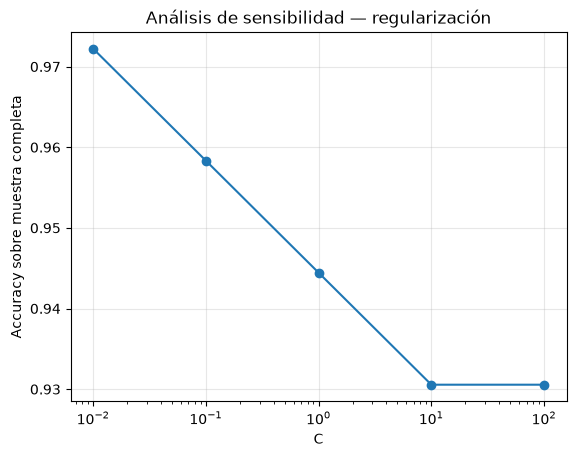

,C,score_descriptivo
0,0.01,0.972222
1,0.10,0.958333
2,1.00,0.944444
3,10.00,0.930556
4,100.00,0.930556


In [4]:
# Sensibilidad al hiperparámetro C
C_values = [0.01, 0.1, 1, 10, 100]
scores = []
for C in C_values:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", C=C, max_iter=1000, random_state=42))
    ])
    model.fit(X, y)
    scores.append(model.score(X, y))

plt.plot(C_values, scores, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy sobre muestra completa")
plt.title("Análisis de sensibilidad — regularización")
plt.grid(alpha=.3)
plt.show()

pd.DataFrame({"C": C_values, "score_descriptivo": scores})


In [5]:
# Modelo interpretable para importancia por permutación
model = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", C=1.0, max_iter=1000, random_state=42))
])
model.fit(X, y)

perm = permutation_importance(model, X, y, n_repeats=30, random_state=42)
imp = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)
display(imp)


,feature,importance_mean,importance_std
0,cosine_similarity,0.142593,0.018262
1,overlap_ratio,0.018981,0.015417
2,length_ratio,-0.000926,0.003464


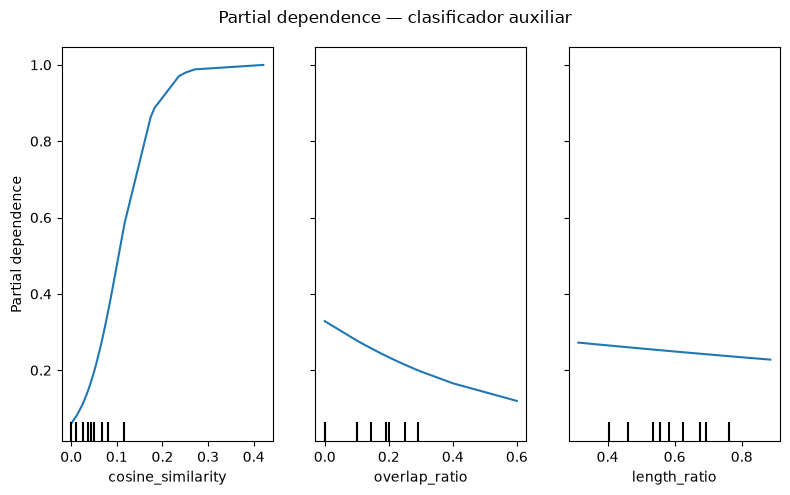

In [6]:
# Partial dependence de las features numéricas
fig, ax = plt.subplots(figsize=(8, 5))
PartialDependenceDisplay.from_estimator(
    model,
    X,
    features=[0, 1, 2],
    feature_names=feature_names,
    ax=ax,
)
plt.suptitle("Partial dependence — clasificador auxiliar")
plt.tight_layout()
plt.show()


## Interpretación

Los resultados de este notebook son exploratorios y deben interpretarse junto con `overfitting_analysis.ipynb`.
No se utilizan para afirmar desempeño operacional. El objetivo es documentar sensibilidad, importancia e interpretación del componente auxiliar que sí posee hiperparámetros supervisados.
